In [1]:
# ============================================
# FINAL EQUALIZER COMPARISON ANALYSIS
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (9, 6)
plt.rcParams["font.size"] = 12

print("Final analysis notebook initialized.")

Final analysis notebook initialized.


In [2]:
# ============================================
# COMMON SIMULATION CONFIGURATION
# ============================================

CONFIG = {
    "modulation": "PAM4",
    "samples_per_symbol": 2,
    "snr_range_db": np.arange(0, 21, 2),
    "reference_snr_db": 14,
    "channel": "FSE optical communication channel",
    "equalization_target": "Symbol recovery",
    "performance_metric": "Bit Error Rate (BER)"
}

print("=== COMMON SIMULATION CONFIGURATION ===")

for key, value in CONFIG.items():
    print(f"{key}: {value}")

=== COMMON SIMULATION CONFIGURATION ===
modulation: PAM4
samples_per_symbol: 2
snr_range_db: [ 0  2  4  6  8 10 12 14 16 18 20]
reference_snr_db: 14
channel: FSE optical communication channel
equalization_target: Symbol recovery
performance_metric: Bit Error Rate (BER)


In [8]:
# ============================================
# COMMON SIMULATION SETTINGS
# ============================================

snr_values = np.arange(0, 21, 2)

reference_snr = 14

modulation = "PAM4"
samples_per_symbol = 2

print("Modulation:", modulation)
print("Samples per symbol:", samples_per_symbol)
print("SNR range:", snr_values)
print("Reference SNR:", reference_snr, "dB")

Modulation: PAM4
Samples per symbol: 2
SNR range: [ 0  2  4  6  8 10 12 14 16 18 20]
Reference SNR: 14 dB


In [9]:
# ============================================
# BER vs SNR RESULTS
# ============================================

baseline_ber = np.array([
    0.278612,
    0.227738,
    0.177262,
    0.130862,
    0.089913,
    0.054400,
    0.026462,
    0.008812,
    0.002363,
    0.000275,
    0.000025
])

lms_ber = np.array([
    0.371988,
    0.236125,
    0.216888,
    0.158963,
    0.144300,
    0.063062,
    0.031988,
    0.009888,
    0.003525,
    0.000188,
    0.000037
])

fse_dfe_ber = np.array([
    0.301331,
    0.242095,
    0.190464,
    0.133330,
    0.077396,
    0.039224,
    0.014509,
    0.002852,
    0.000350,
    0.000000,
    0.000000
])

cnn_ber = np.array([
    0.270968,
    0.231283,
    0.181970,
    0.123606,
    0.075344,
    0.035759,
    0.012153,
    0.002401,
    0.000200,
    0.000000,
    0.000000
])

lstm_ber = np.array([
    0.327210,
    0.302683,
    0.278256,
    0.237211,
    0.206327,
    0.165332,
    0.125438,
    0.092502,
    0.071328,
    0.055611,
    0.050856
])

print("All BER arrays loaded.")
print("Number of SNR points:", len(snr_values))

All BER arrays loaded.
Number of SNR points: 11


In [10]:
# ============================================
# DATA VALIDATION
# ============================================

ber_results = {
    "Baseline": baseline_ber,
    "LMS": lms_ber,
    "FSE-DFE": fse_dfe_ber,
    "CNN": cnn_ber,
    "LSTM": lstm_ber
}

print("=== BER DATA VALIDATION ===")

for method, ber in ber_results.items():
    print(
        f"{method:10s} | "
        f"Points: {len(ber):2d} | "
        f"14 dB BER: {ber[snr_values == reference_snr][0]:.6f} | "
        f"Min BER: {np.min(ber):.6f} | "
        f"Max BER: {np.max(ber):.6f}"
    )

assert all(len(ber) == len(snr_values) for ber in ber_results.values())

print("\n✓ All BER arrays match the SNR grid.")

=== BER DATA VALIDATION ===
Baseline   | Points: 11 | 14 dB BER: 0.008812 | Min BER: 0.000025 | Max BER: 0.278612
LMS        | Points: 11 | 14 dB BER: 0.009888 | Min BER: 0.000037 | Max BER: 0.371988
FSE-DFE    | Points: 11 | 14 dB BER: 0.002852 | Min BER: 0.000000 | Max BER: 0.301331
CNN        | Points: 11 | 14 dB BER: 0.002401 | Min BER: 0.000000 | Max BER: 0.270968
LSTM       | Points: 11 | 14 dB BER: 0.092502 | Min BER: 0.050856 | Max BER: 0.327210

✓ All BER arrays match the SNR grid.


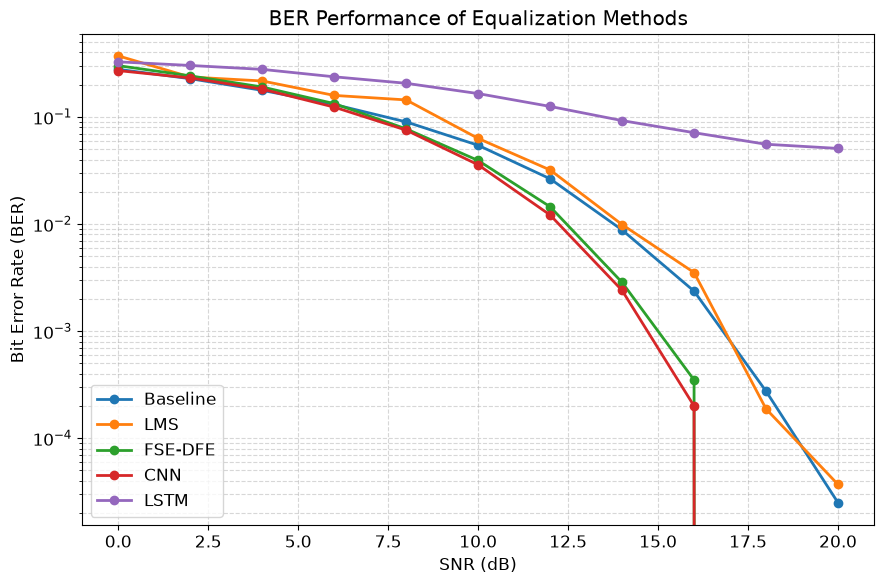

In [11]:
# ============================================
# BER vs SNR
# ============================================

plt.figure(figsize=(9, 6))

for method, ber in ber_results.items():
    plt.semilogy(
        snr_values,
        ber,
        marker="o",
        linewidth=2,
        label=method
    )

plt.xlabel("SNR (dB)")
plt.ylabel("Bit Error Rate (BER)")
plt.title("BER Performance of Equalization Methods")
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()

plt.show()

In [12]:
# ============================================
# COMPLEXITY AND TIMING RESULTS
# ============================================

complexity_results = pd.DataFrame({
    "Method": [
        "Baseline",
        "LMS",
        "FSE-DFE",
        "CNN",
        "LSTM"
    ],

    "Parameters": [
        0,
        5,
        8,
        6916,
        4612
    ],

    "Training_or_Adaptation_s": [
        np.nan,
        0.018043,
        0.108364,
        29.013223,
        14.137788
    ],

    "Inference_Time_s": [
        np.nan,
        0.014055,
        0.073483,
        0.000516,
        0.002447
    ]
})

complexity_results

,Method,Parameters,Training_or_Adaptation_s,Inference_Time_s
0,Baseline,0,NaN,NaN
1,LMS,5,0.018043,0.014055
2,FSE-DFE,8,0.108364,0.073483
3,CNN,6916,29.013223,0.000516
4,LSTM,4612,14.137788,0.002447


In [13]:
# ============================================
# 14 dB PERFORMANCE COMPARISON
# ============================================

ber_at_14db = {
    "Baseline": 0.008812,
    "LMS": 0.009888,
    "FSE-DFE": 0.002852,
    "CNN": 0.002401,
    "LSTM": 0.092502
}

comparison = complexity_results.copy()

comparison["BER_14dB"] = comparison["Method"].map(ber_at_14db)

comparison = comparison[
    [
        "Method",
        "BER_14dB",
        "Parameters",
        "Training_or_Adaptation_s",
        "Inference_Time_s"
    ]
]

comparison

,Method,BER_14dB,Parameters,Training_or_Adaptation_s,Inference_Time_s
0,Baseline,0.008812,0,NaN,NaN
1,LMS,0.009888,5,0.018043,0.014055
2,FSE-DFE,0.002852,8,0.108364,0.073483
3,CNN,0.002401,6916,29.013223,0.000516
4,LSTM,0.092502,4612,14.137788,0.002447


In [14]:
# ============================================
# BER IMPROVEMENT RELATIVE TO BASELINE
# ============================================

baseline_ber_14db = ber_at_14db["Baseline"]

comparison["BER_Improvement_vs_Baseline_%"] = (
    (baseline_ber_14db - comparison["BER_14dB"])
    / baseline_ber_14db
) * 100

comparison

,Method,BER_14dB,Parameters,Training_or_Adaptation_s,Inference_Time_s,BER_Improvement_vs_Baseline_%
0,Baseline,0.008812,0,NaN,NaN,0.000000
1,LMS,0.009888,5,0.018043,0.014055,-12.210622
2,FSE-DFE,0.002852,8,0.108364,0.073483,67.635043
3,CNN,0.002401,6916,29.013223,0.000516,72.753064
4,LSTM,0.092502,4612,14.137788,0.002447,-949.727644


In [17]:
# ============================================
# FINAL CONSOLIDATED RESULTS
# ============================================

final_results = pd.DataFrame({
    "Method": [
        "Baseline",
        "LMS",
        "FSE-DFE",
        "CNN",
        "LSTM"
    ],

    "BER_14dB": [
        0.008812,
        0.009888,
        0.002852,
        0.002401,
        0.092502
    ],

    "Parameters": [
        0,
        5,
        8,
        6916,
        4612
    ],

    "Training_Time_s": [
        0,
        0.018043,
        0.108364,
        29.013223,
        14.137788
    ],

    "Inference_Time_s": [
        0,
        0.020390,
        0.092978,
        0.000597,
        0.001571
    ]
})

final_results

,Method,BER_14dB,Parameters,Training_Time_s,Inference_Time_s
0,Baseline,0.008812,0,0.000000,0.000000
1,LMS,0.009888,5,0.018043,0.020390
2,FSE-DFE,0.002852,8,0.108364,0.092978
3,CNN,0.002401,6916,29.013223,0.000597
4,LSTM,0.092502,4612,14.137788,0.001571


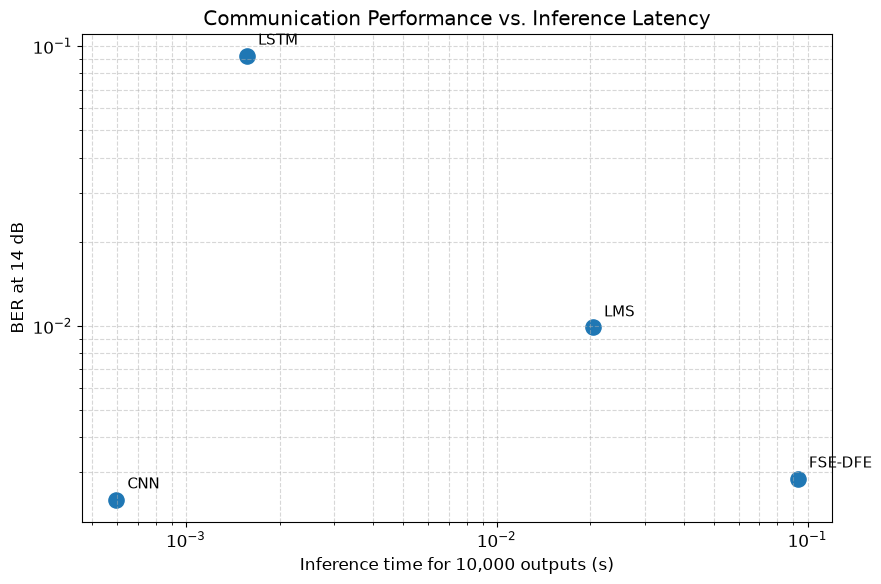

In [18]:
# ============================================
# PERFORMANCE vs INFERENCE LATENCY
# ============================================

plot_results = final_results.copy()

# Exclude baseline because it has no equalization inference stage
plot_results = plot_results[
    plot_results["Method"] != "Baseline"
].copy()

plt.figure(figsize=(9, 6))

plt.scatter(
    plot_results["Inference_Time_s"],
    plot_results["BER_14dB"],
    s=120
)

for _, row in plot_results.iterrows():
    plt.annotate(
        row["Method"],
        (
            row["Inference_Time_s"],
            row["BER_14dB"]
        ),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=11
    )

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Inference time for 10,000 outputs (s)")
plt.ylabel("BER at 14 dB")
plt.title("Communication Performance vs. Inference Latency")

plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.tight_layout()

plt.show()

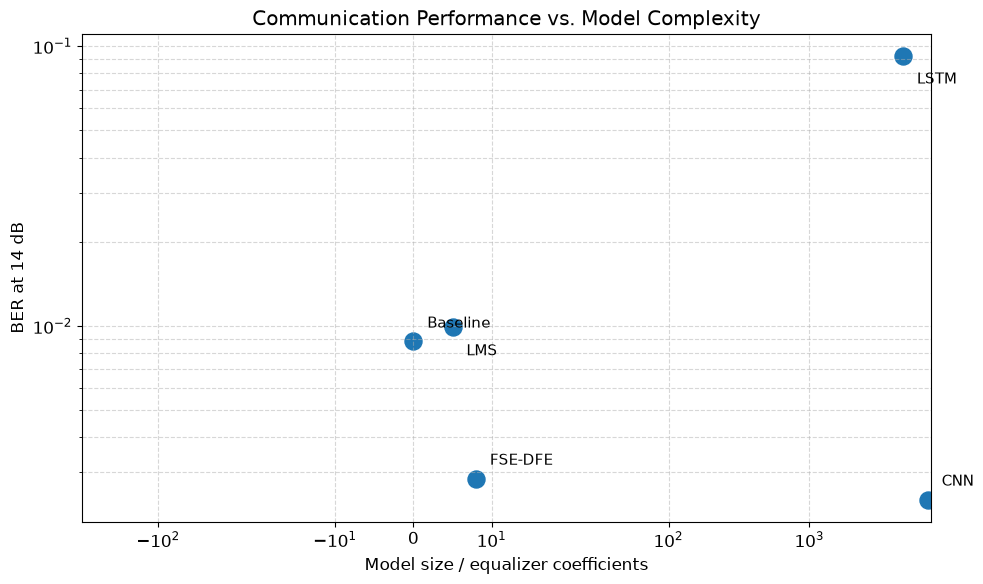

In [21]:
# ============================================
# MODEL COMPLEXITY vs BER
# ============================================

plt.figure(figsize=(10, 6))

plt.scatter(
    final_results["Parameters"],
    final_results["BER_14dB"],
    s=150
)

for _, row in final_results.iterrows():

    if row["Method"] == "Baseline":
        offset = (10, 10)

    elif row["Method"] == "LMS":
        offset = (10, -20)

    elif row["Method"] == "FSE-DFE":
        offset = (10, 10)

    elif row["Method"] == "CNN":
        offset = (10, 10)

    elif row["Method"] == "LSTM":
        offset = (10, -20)

    plt.annotate(
        row["Method"],
        (row["Parameters"], row["BER_14dB"]),
        xytext=offset,
        textcoords="offset points",
        fontsize=11
    )

# Log scale for BER
plt.yscale("log")

# Symlog allows x = 0 while still expanding small values
plt.xscale("symlog", linthresh=20)

plt.xlabel("Model size / equalizer coefficients")
plt.ylabel("BER at 14 dB")
plt.title("Communication Performance vs. Model Complexity")

plt.grid(
    True,
    which="both",
    linestyle="--",
    alpha=0.5
)

plt.tight_layout()
plt.show()

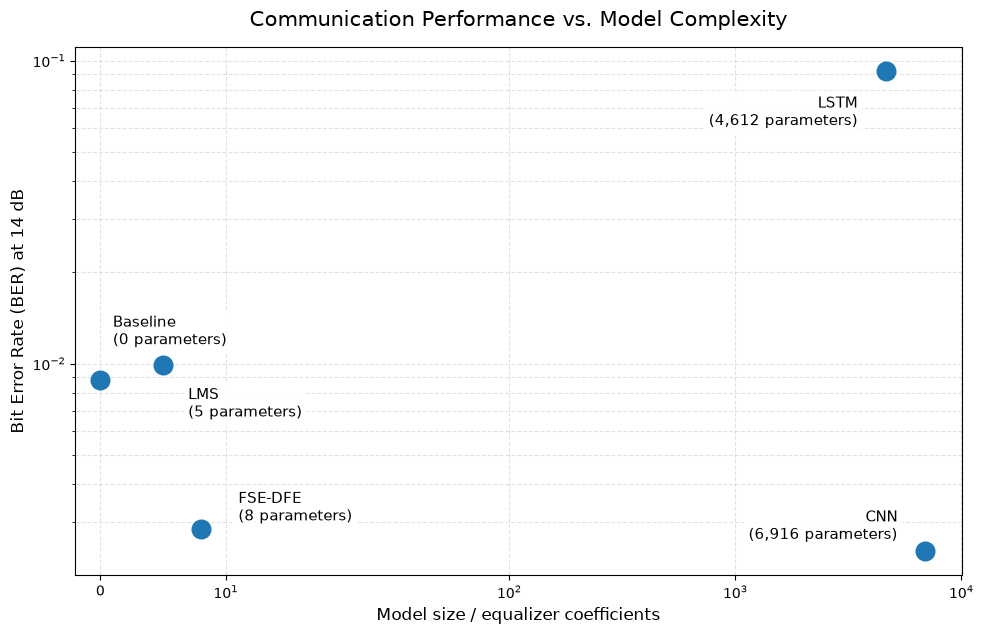

In [29]:
# ============================================
# FINAL TRADE-OFF FIGURE
# ============================================

fig, ax = plt.subplots(figsize=(10, 6.5))

# X-axis: symlog allows the baseline at x = 0
# while still separating the small classical equalizer models
ax.set_xscale("symlog", linthresh=20)
ax.set_xlim(left=-2, right=10000)

# BER spans multiple orders of magnitude
ax.set_yscale("log")

# Plot all methods
ax.scatter(
    final_results["Parameters"],
    final_results["BER_14dB"],
    s=180,
    zorder=3
)

# Manually positioned labels
label_positions = {
    "Baseline": (9, 35),
    "LMS": (18, -28),
    "FSE-DFE": (27, 15),
    "LSTM": (-20, -30),
    "CNN": (-20, 18)
}

for _, row in final_results.iterrows():

    method = row["Method"]
    x = row["Parameters"]
    y = row["BER_14dB"]

    offset = label_positions[method]

    ax.annotate(
        f"{method}\n({int(x):,} parameters)",
        (x, y),
        xytext=offset,
        textcoords="offset points",
        fontsize=10.5,
        color="black",
        ha="left" if offset[0] > 0 else "right",
        va="center",
        bbox=dict(
            boxstyle="round,pad=0.3",
            facecolor="white",
            edgecolor="none",
            alpha=0.92
        )
    )

# Axis labels
ax.set_xlabel(
    "Model size / equalizer coefficients",
    fontsize=12
)

ax.set_ylabel(
    "Bit Error Rate (BER) at 14 dB",
    fontsize=12
)

# Title
ax.set_title(
    "Communication Performance vs. Model Complexity",
    fontsize=15,
    pad=15
)

# Grid
ax.grid(
    True,
    which="both",
    linestyle="--",
    alpha=0.35
)

# Tick formatting
ax.tick_params(
    axis="both",
    labelsize=10
)

plt.tight_layout()
plt.show()